In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import os

file_path = r"C:\Users\brisa\telco-customer-churn-analysis\data\raw\WA_Fn-UseC_-Telco-Customer-Churn.csv"
df = pd.read_csv(file_path)
## dataset shape
print("Dataset Shape:", df.shape)

print(df.head()) #check first few rowns

# print information
print(df.info())

Dataset Shape: (7043, 21)
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingM

In [7]:

if 'customerID' in df.columns: ##get rid of the customerid column because it is not relevant to prediction
    df.drop('customerID', axis=1, inplace=True)

df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0}) ##maps churn yes/no values to binary 0/1 so the model can read it

##handles the issue of empty strings in total charges
# fills these missing values with the median 
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges']= df['TotalCharges'].fillna(df['TotalCharges'].median())

X = df.drop('Churn',axis=1) ##drop churn from features
y= df['Churn'] ##identify it as target

#one-hot encode the categories of the remaining features, using drop first to avoid linear dependency 
X = pd.get_dummies(X, drop_first=True)


print("Feature matrix after changes =", X.shape)
print("\nFirst five rows of the matrix=")
display(X.head())

Feature matrix after changes = (7043, 30)

First five rows of the matrix=


C:\Users\brisa\AppData\Local\Temp\ipykernel_17636\1669792581.py:2: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop('customerID', axis=1, inplace=True)


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,False,True,False,False,True,False,...,False,False,False,False,False,False,True,False,True,False
1,0,34,56.95,1889.50,True,False,False,True,False,False,...,False,False,False,False,True,False,False,False,False,True
2,0,2,53.85,108.15,True,False,False,True,False,False,...,False,False,False,False,False,False,True,False,False,True
3,0,45,42.30,1840.75,True,False,False,False,True,False,...,False,False,False,False,True,False,False,False,False,False
4,0,2,70.70,151.65,False,False,False,True,False,False,...,False,False,False,False,False,False,True,False,True,False


In [10]:
##split the data into an 80/20 training test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)



Training features shape: (5634, 30)
Testing features shape: (1409, 30)


In [13]:
# save the clean and split data into the processed data folder

X_train.to_csv(r"C:\Users\brisa\telco-customer-churn-analysis\data\processed\X_train.csv", index=False)
X_test.to_csv(r"C:\Users\brisa\telco-customer-churn-analysis\data\processed\X_test.csv", index=False)
y_train.to_csv(r"C:\Users\brisa\telco-customer-churn-analysis\data\processed\y_train.csv", index=False)
y_test.to_csv(r"C:\Users\brisa\telco-customer-churn-analysis\data\processed\y_test.csv", index=False)



C:\Users\brisa\AppData\Local\Temp\ipykernel_17636\2182343915.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=vizDf, x='Churn',palette='viridis')


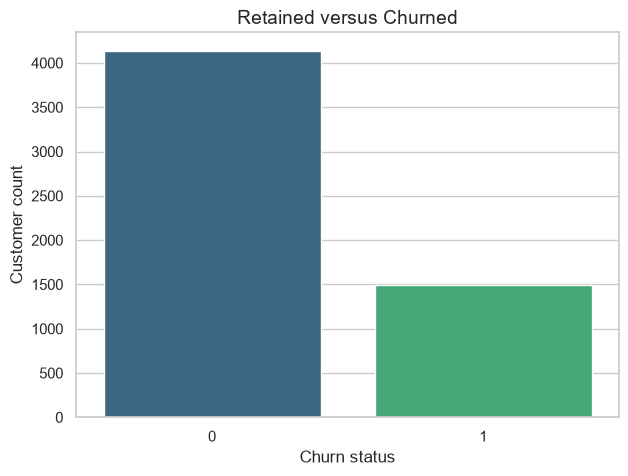

In [18]:
pathDir = r"C:\Users\brisa\telco-customer-churn-analysis\data\processed"
X_trainViz = pd.read_csv(f"{pathDir}\\X_train.csv")
y_train_viz= pd.read_csv(f"{pathDir}\\y_train.csv")

vizDf =X_trainViz.copy()
vizDf['Churn'] =y_train_viz['Churn'] ##combine training sets for plotting

sns.set_theme(style="whitegrid")
plt.figure(figsize=(7, 5))

##plot count in each class
sns.countplot(data=vizDf, x='Churn',palette='viridis')
plt.title('Retained versus Churned',fontsize=14)
plt.ylabel('Customer count')
plt.xlabel('Churn status')

plt.show()


Training Set exhibits a large class imbalance.

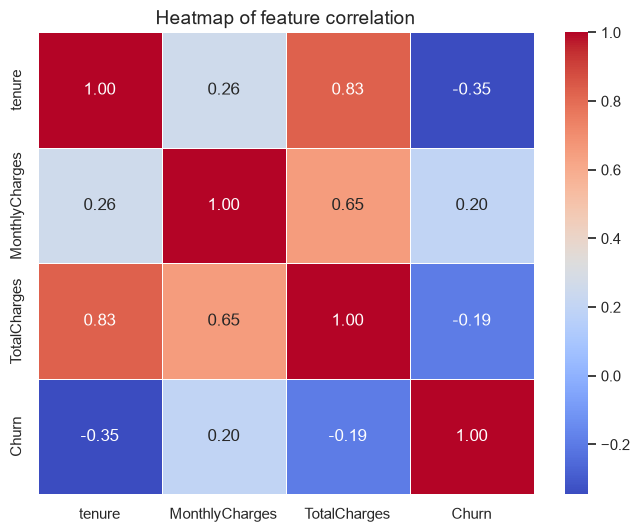

In [21]:
plt.figure(figsize=(8, 6))

numCats = ['tenure','MonthlyCharges', 'TotalCharges','Churn']##identify the numeric attributes
correlationMatrix = vizDf[numCats].corr()

sns.heatmap(correlationMatrix,annot=True, cmap='coolwarm',fmt=".2f", linewidths=0.5)
plt.title('Heatmap of feature correlation', fontsize=14)
plt.show()

The heatmap shows the correlation between the numeric attributes. 